# SMD Data Ingestion and Preprocessing Pipeline

This notebook implements the data ingestion, exploratory analysis, and preprocessing pipeline for the Server Machine Dataset (SMD).

The analysis is performed independently for each server (machine), as recommended by the original SMD dataset structure.

In [ ]:
import os
import numpy as np
import pandas as pd
import csv
import matplotlib.pyplot as plt
import random
import seaborn as sns
from sklearn.preprocessing import StandardScaler

output_folder = "preprocess"


In [ ]:
# !rm -rf /content/preprocess

## 1. Data Ingestion

The original SMD files are loaded and converted into a structured format for further analysis.

For each machine, the following data components are considered:

- `train` – training time series;
- `test` – testing time series;
- `test_label` – point-level anomaly labels for the test set;
- `interpretation_label` – information about the dimensions associated with each anomaly.

Each machine is processed independently.

In [ ]:
def load_and_save(category, filename, dataset_path):
  input_path = os.path.join(dataset_path, category, filename)

  data = np.genfromtxt(input_path, dtype=np.float32, delimiter=',')
  machine_name = os.path.splitext(filename)[0]

  print(machine_name, category, data.shape)

  category_output = os.path.join(output_folder, category)
  os.makedirs(category_output, exist_ok=True)

  output_path = os.path.join(
      category_output,
      f"{machine_name}.csv"
  )

  np.savetxt(
      output_path,
      data,
      delimiter=','
  )

In [ ]:
def load_interpretation_label(filename, interpretation_path):
  path = os.path.join(interpretation_path, filename)

  with open(path, "r") as file:
    lines = file.readlines()

  machine_name = os.path.splitext(filename)[0]

  print(machine_name, "interpretation_label")
  print(lines[:5])

  return lines

In [ ]:
def load_data(dataset_path):
  os.makedirs(output_folder, exist_ok=True)

  for category in ["train", "test", "test_label"]:
    category_path = os.path.join(dataset_path, category)
    for filename in os.listdir(category_path):
      if filename.endswith(".txt"):
        load_and_save(category, filename, dataset_path)

  #Interpretation label which has different file structure from the other files (train, test, test_label)
  interpretation_path = os.path.join(dataset_path, "interpretation_label")

  for filename in os.listdir(interpretation_path):
    if filename.endswith(".txt"):
      load_interpretation_label(filename, interpretation_path)

In [ ]:
path = "/content/drive/MyDrive/ServerMachineDataset"
load_data(path)

machine-2-6 train (28743, 38)
machine-3-11 train (28695, 38)
machine-1-6 train (23688, 38)
machine-3-5 train (23690, 38)
machine-3-2 train (23702, 38)
machine-3-1 train (28700, 38)
machine-2-5 train (23688, 38)
machine-2-7 train (23696, 38)
machine-2-1 train (23693, 38)
machine-2-4 train (23689, 38)
machine-3-10 train (23692, 38)
machine-1-1 train (28479, 38)
machine-2-2 train (23699, 38)
machine-1-3 train (23702, 38)
machine-1-8 train (23698, 38)
machine-2-3 train (23688, 38)
machine-2-9 train (28722, 38)
machine-3-6 train (28726, 38)
machine-1-7 train (23697, 38)
machine-1-4 train (23706, 38)
machine-3-9 train (28713, 38)
machine-3-4 train (23687, 38)
machine-3-8 train (28703, 38)
machine-1-2 train (23694, 38)
machine-3-3 train (23703, 38)
machine-2-8 train (23702, 38)
machine-1-5 train (23705, 38)
machine-3-7 train (28705, 38)
machine-3-7 test (28705, 38)
machine-2-6 test (28743, 38)
machine-1-7 test (23697, 38)
machine-1-8 test (23699, 38)
machine-1-6 test (23689, 38)
machine-1-4 t

## 2. Exploratory Data Analysis (EDA)

Exploratory analysis is first performed on `machine-1-1` to understand the structure and characteristics of the SMD data.

The analysis includes:

1. dataset shape and data types;
2. missing values;
3. constant features;
4. feature distributions;
5. potential outliers;
6. correlations between features;
7. anomaly distribution in the test set.

### 2.1 Data Structure

Each row represents one timestep and each column represents one monitored feature.

SMD contains 38 features per machine. Therefore, the data for one machine have the general shape:

`(N, 38)`

where `N` is the number of temporal observations.

In [ ]:
# inspect first machine
df_train = pd.read_csv('/content/preprocess/train/machine-1-1.csv', header=None, dtype="float32")
df_test = pd.read_csv('/content/preprocess/test/machine-1-1.csv', header=None, dtype="float32")

df_train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28479 entries, 0 to 28478
Data columns (total 38 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       28479 non-null  float32
 1   1       28479 non-null  float32
 2   2       28479 non-null  float32
 3   3       28479 non-null  float32
 4   4       28479 non-null  float32
 5   5       28479 non-null  float32
 6   6       28479 non-null  float32
 7   7       28479 non-null  float32
 8   8       28479 non-null  float32
 9   9       28479 non-null  float32
 10  10      28479 non-null  float32
 11  11      28479 non-null  float32
 12  12      28479 non-null  float32
 13  13      28479 non-null  float32
 14  14      28479 non-null  float32
 15  15      28479 non-null  float32
 16  16      28479 non-null  float32
 17  17      28479 non-null  float32
 18  18      28479 non-null  float32
 19  19      28479 non-null  float32
 20  20      28479 non-null  float32
 21  21      28479 non-null  float32
 22

In [ ]:
print("\nFirst rows:")
print(df_train.head())


First rows:
         0         1         2         3    4         5         6    7   \
0  0.032258  0.039195  0.027871  0.024390  0.0  0.915385  0.343691  0.0   
1  0.043011  0.048729  0.033445  0.025552  0.0  0.915385  0.344633  0.0   
2  0.043011  0.034958  0.032330  0.025552  0.0  0.915385  0.344633  0.0   
3  0.032258  0.028602  0.030100  0.024390  0.0  0.912821  0.342750  0.0   
4  0.032258  0.019068  0.026756  0.023229  0.0  0.912821  0.342750  0.0   

         8         9   ...   28        29        30        31   32        33  \
0  0.020011  0.000122  ...  0.0  0.004298  0.029993  0.022131  0.0  0.000045   
1  0.019160  0.001722  ...  0.0  0.004298  0.030041  0.028821  0.0  0.000045   
2  0.020011  0.000122  ...  0.0  0.004298  0.026248  0.021101  0.0  0.000045   
3  0.021289  0.000000  ...  0.0  0.004298  0.030169  0.025733  0.0  0.000022   
4  0.018734  0.000000  ...  0.0  0.004298  0.027240  0.022645  0.0  0.000034   

         34        35   36   37  
0  0.034677  0.034747

In [ ]:
def get_random_color():
    return (random.random(), random.random(), random.random())

# Plotting function to display 3 plots per row
def plot_scatter(data, title):
    n_cols = 3
    n_rows = (len(data.columns.tolist()) + n_cols - 1) // n_cols  # Calculate the number of rows needed

    plt.figure(figsize=(15, 5 * n_rows))
    for i, col in enumerate(data.columns.tolist()):
        plt.subplot(n_rows, n_cols, i + 1)
        plt.scatter(data.index, data[col], color=get_random_color(), alpha=0.7)
        plt.title(f'Scatter Plot of {col}')
        plt.xlabel('Index')
        plt.ylabel(col)
        plt.xticks(rotation=45)

    plt.tight_layout(h_pad=3)
    plt.suptitle(title, fontsize=16, y=1.02)
    plt.show()

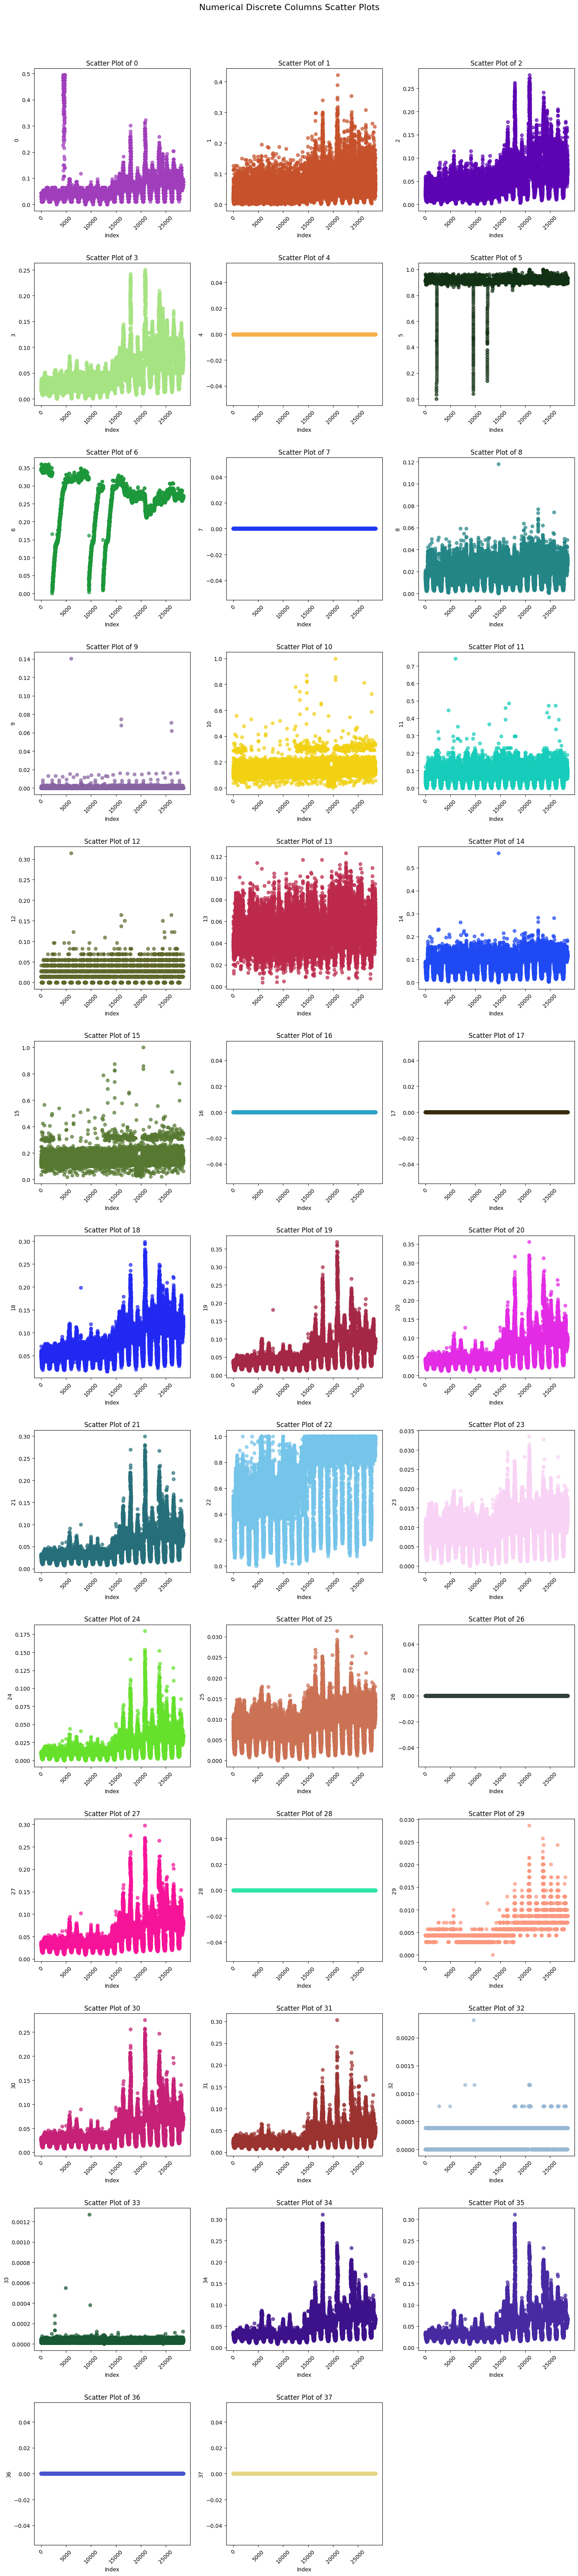

In [ ]:
plot_scatter(df_train, "Numerical Discrete Columns Scatter Plots")

### 2.2 Feature Correlation

The Pearson correlation matrix is inspected to identify strongly related features.

High correlations indicate that some variables exhibit similar behaviour. `NaN` correlations may appear for constant features because their standard deviation is zero.

Correlated features are not automatically removed because relationships between variables may be relevant for multivariate anomaly detection.

In [ ]:
plt.figure(figsize = (12,12))
sns.heatmap(df_train.corr(), cmap='coolwarm', annot = True)
plt.show()

In [ ]:
corr_matrix = df_train.corr()
corr_matrix

,0,1,2,3,4,5,6,7,8,9,...,28,29,30,31,32,33,34,35,36,37
0,1.000000,0.499984,0.593295,0.610378,NaN,0.144292,0.073279,NaN,0.289500,-0.003432,...,NaN,0.548952,0.617884,0.589149,0.284943,0.005519,0.613064,0.613068,NaN,NaN
1,0.499984,1.000000,0.895725,0.826255,NaN,0.165566,0.040909,NaN,0.370442,0.000811,...,NaN,0.681678,0.783919,0.740887,0.380382,0.015139,0.775908,0.775910,NaN,NaN
2,0.593295,0.895725,1.000000,0.976611,NaN,0.197107,0.048144,NaN,0.436661,0.005113,...,NaN,0.803180,0.928814,0.871917,0.448243,0.011475,0.920715,0.920716,NaN,NaN
3,0.610378,0.826255,0.976611,1.000000,NaN,0.202340,0.048586,NaN,0.438673,0.006558,...,NaN,0.821310,0.957484,0.889662,0.464330,0.011336,0.950201,0.950200,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.144292,0.165566,0.197107,0.202340,NaN,1.000000,0.235799,NaN,0.108087,-0.003678,...,NaN,0.150233,0.204537,0.186983,0.092767,-0.006391,0.214043,0.214044,NaN,NaN
6,0.073279,0.040909,0.048144,0.048586,NaN,0.235799,1.000000,NaN,-0.003539,0.004843,...,NaN,0.014970,0.057775,0.079508,0.016100,-0.001801,0.059898,0.059904,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0.289500,0.370442,0.436661,0.438673,NaN,0.108087,-0.003539,NaN,1.000000,0.020568,...,NaN,0.395712,0.496971,0.465653,0.421758,0.016690,0.451705,0.451723,NaN,NaN
9,-0.003432,0.000811,0.005113,0.006558,NaN,-0.003678,0.004843,NaN,0.020568,1.000000,...,NaN,0.003034,0.005908,0.002511,0.010843,0.007236,0.006490,0.006496,NaN,NaN


### 2.3 Potential Outliers

Boxplots are used to visually inspect extreme observations.

In an anomaly detection problem, points outside the boxplot whiskers are not automatically removed because they may represent meaningful system behaviour rather than measurement errors.

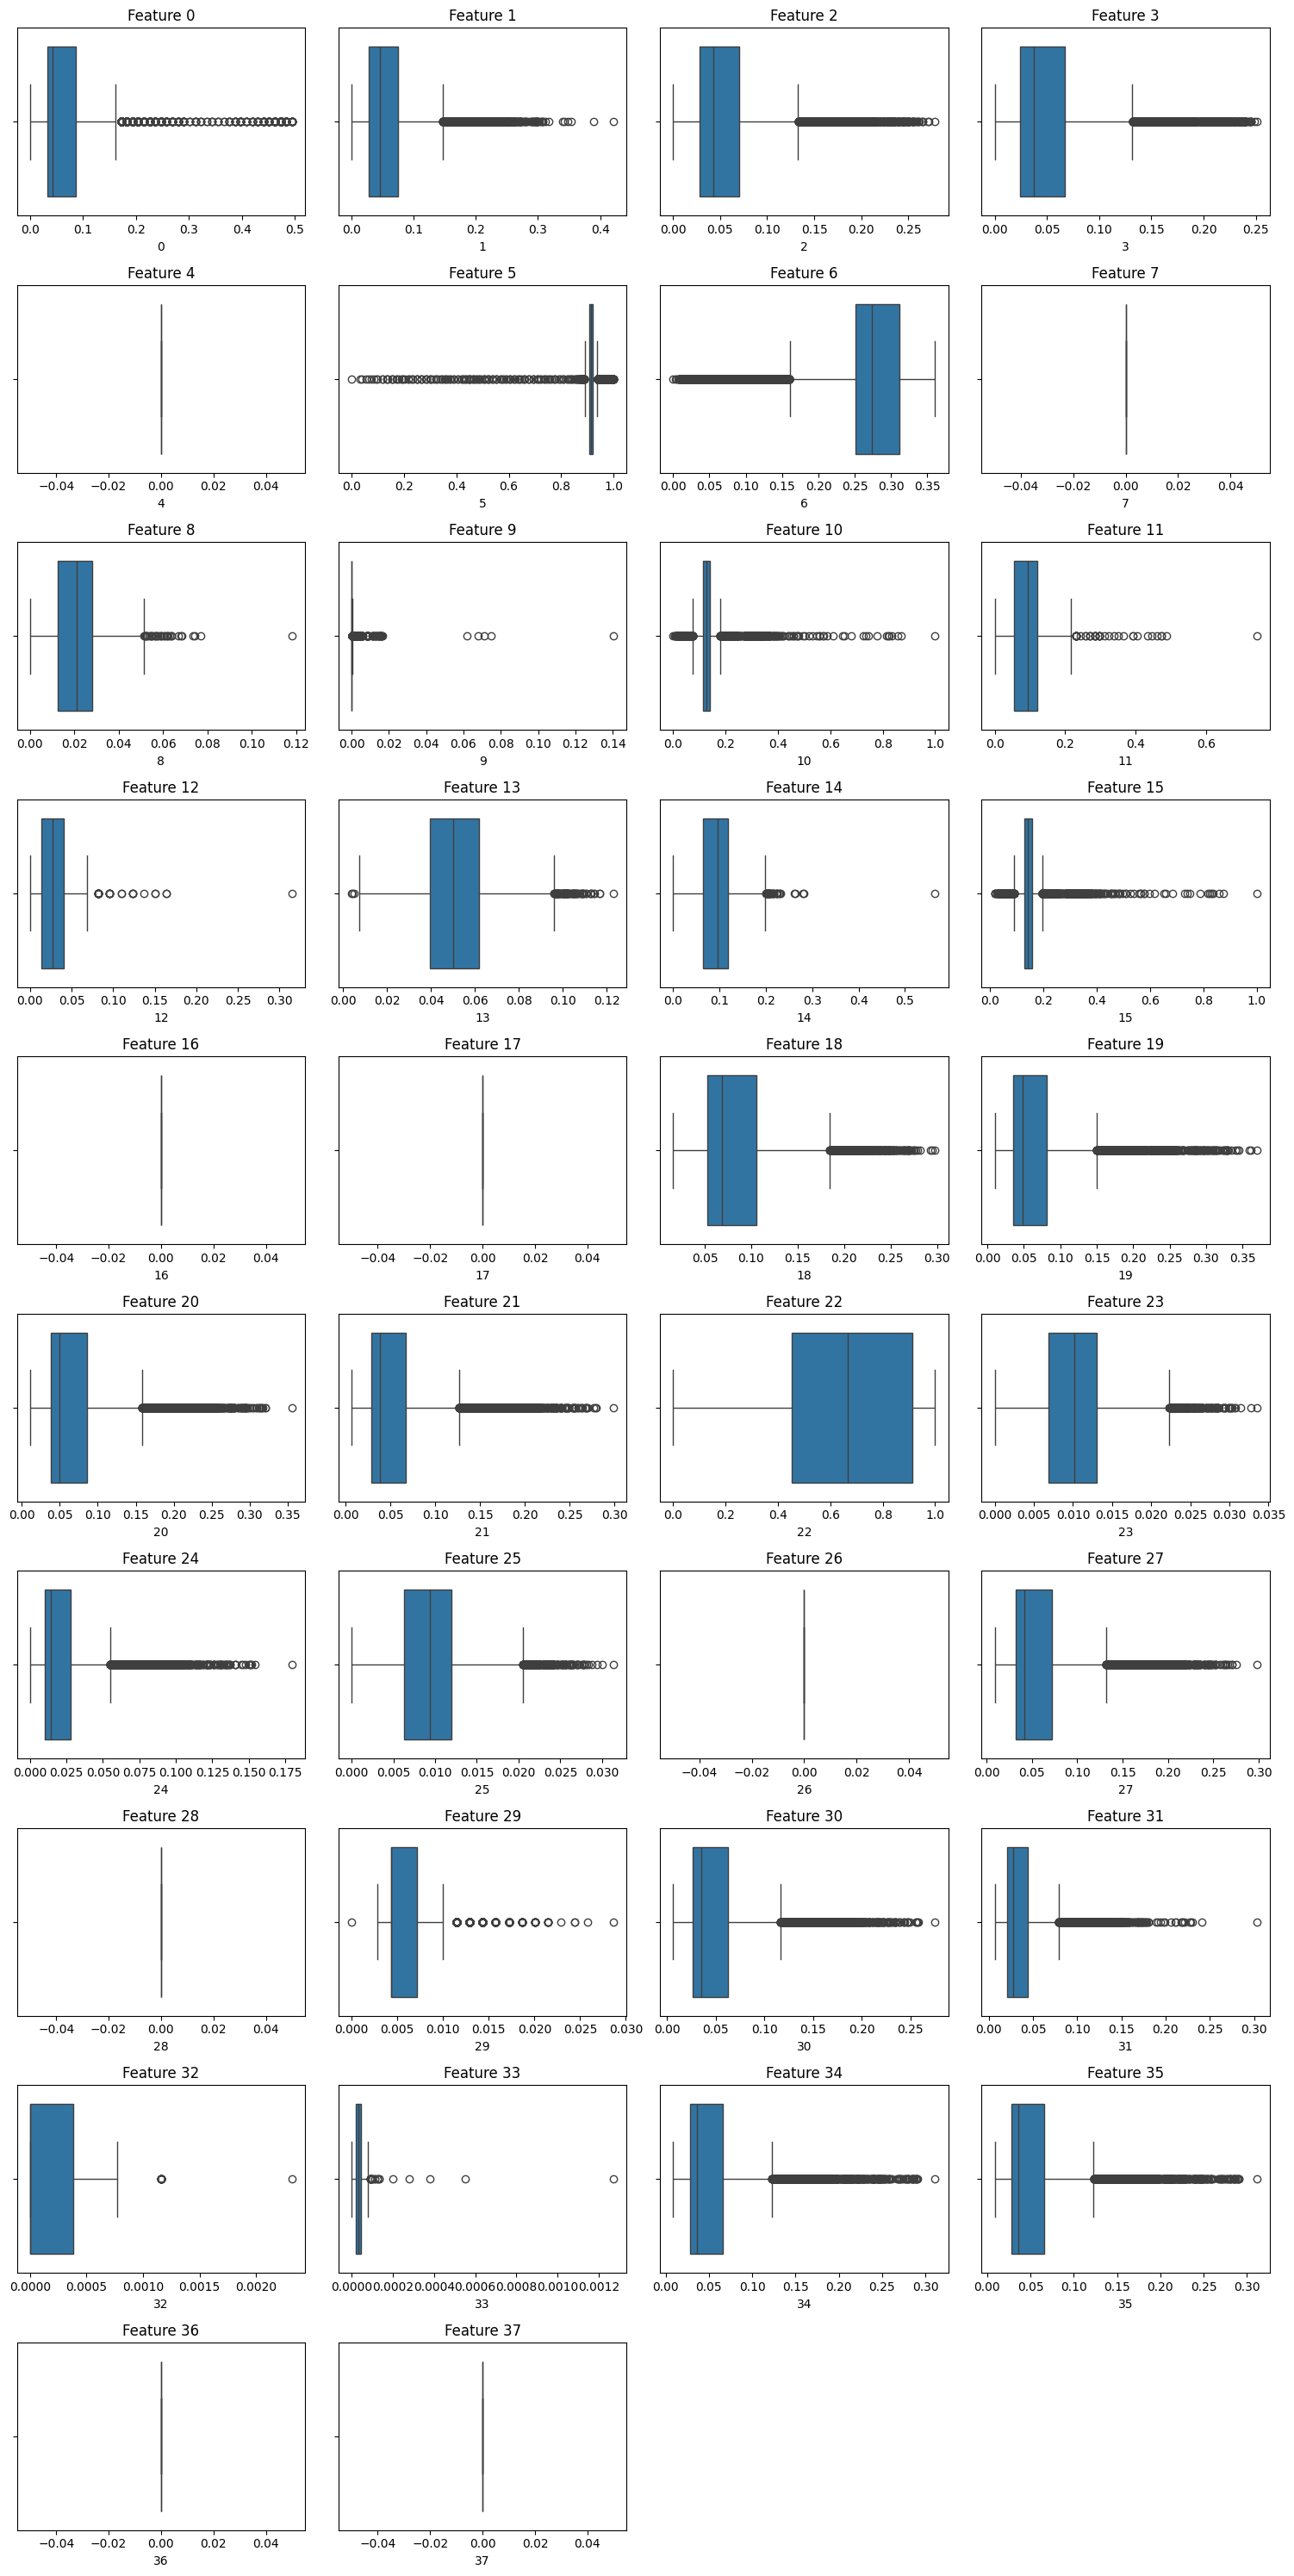

In [ ]:
#boxplots to detect outliers in numerical data (discrete)
plt.figure(figsize=(15,30))
for i, col in enumerate(df_train.columns.to_list()):
    plt.subplot(10,4, i+1)# sublot on which our boxplot is drawn for identifying outlier
    sns.boxplot(x=df_train[col])
    plt.title(f"Feature {col}")

plt.tight_layout()  # compact and spacing between plots
plt.show()

### 2.4 Feature Distributions

Histograms are used to inspect the distribution of each numerical feature.

Several SMD features may exhibit skewed or non-Gaussian distributions. These distributions are inspected but are not automatically transformed, since unusual values may contain information relevant to anomaly detection.

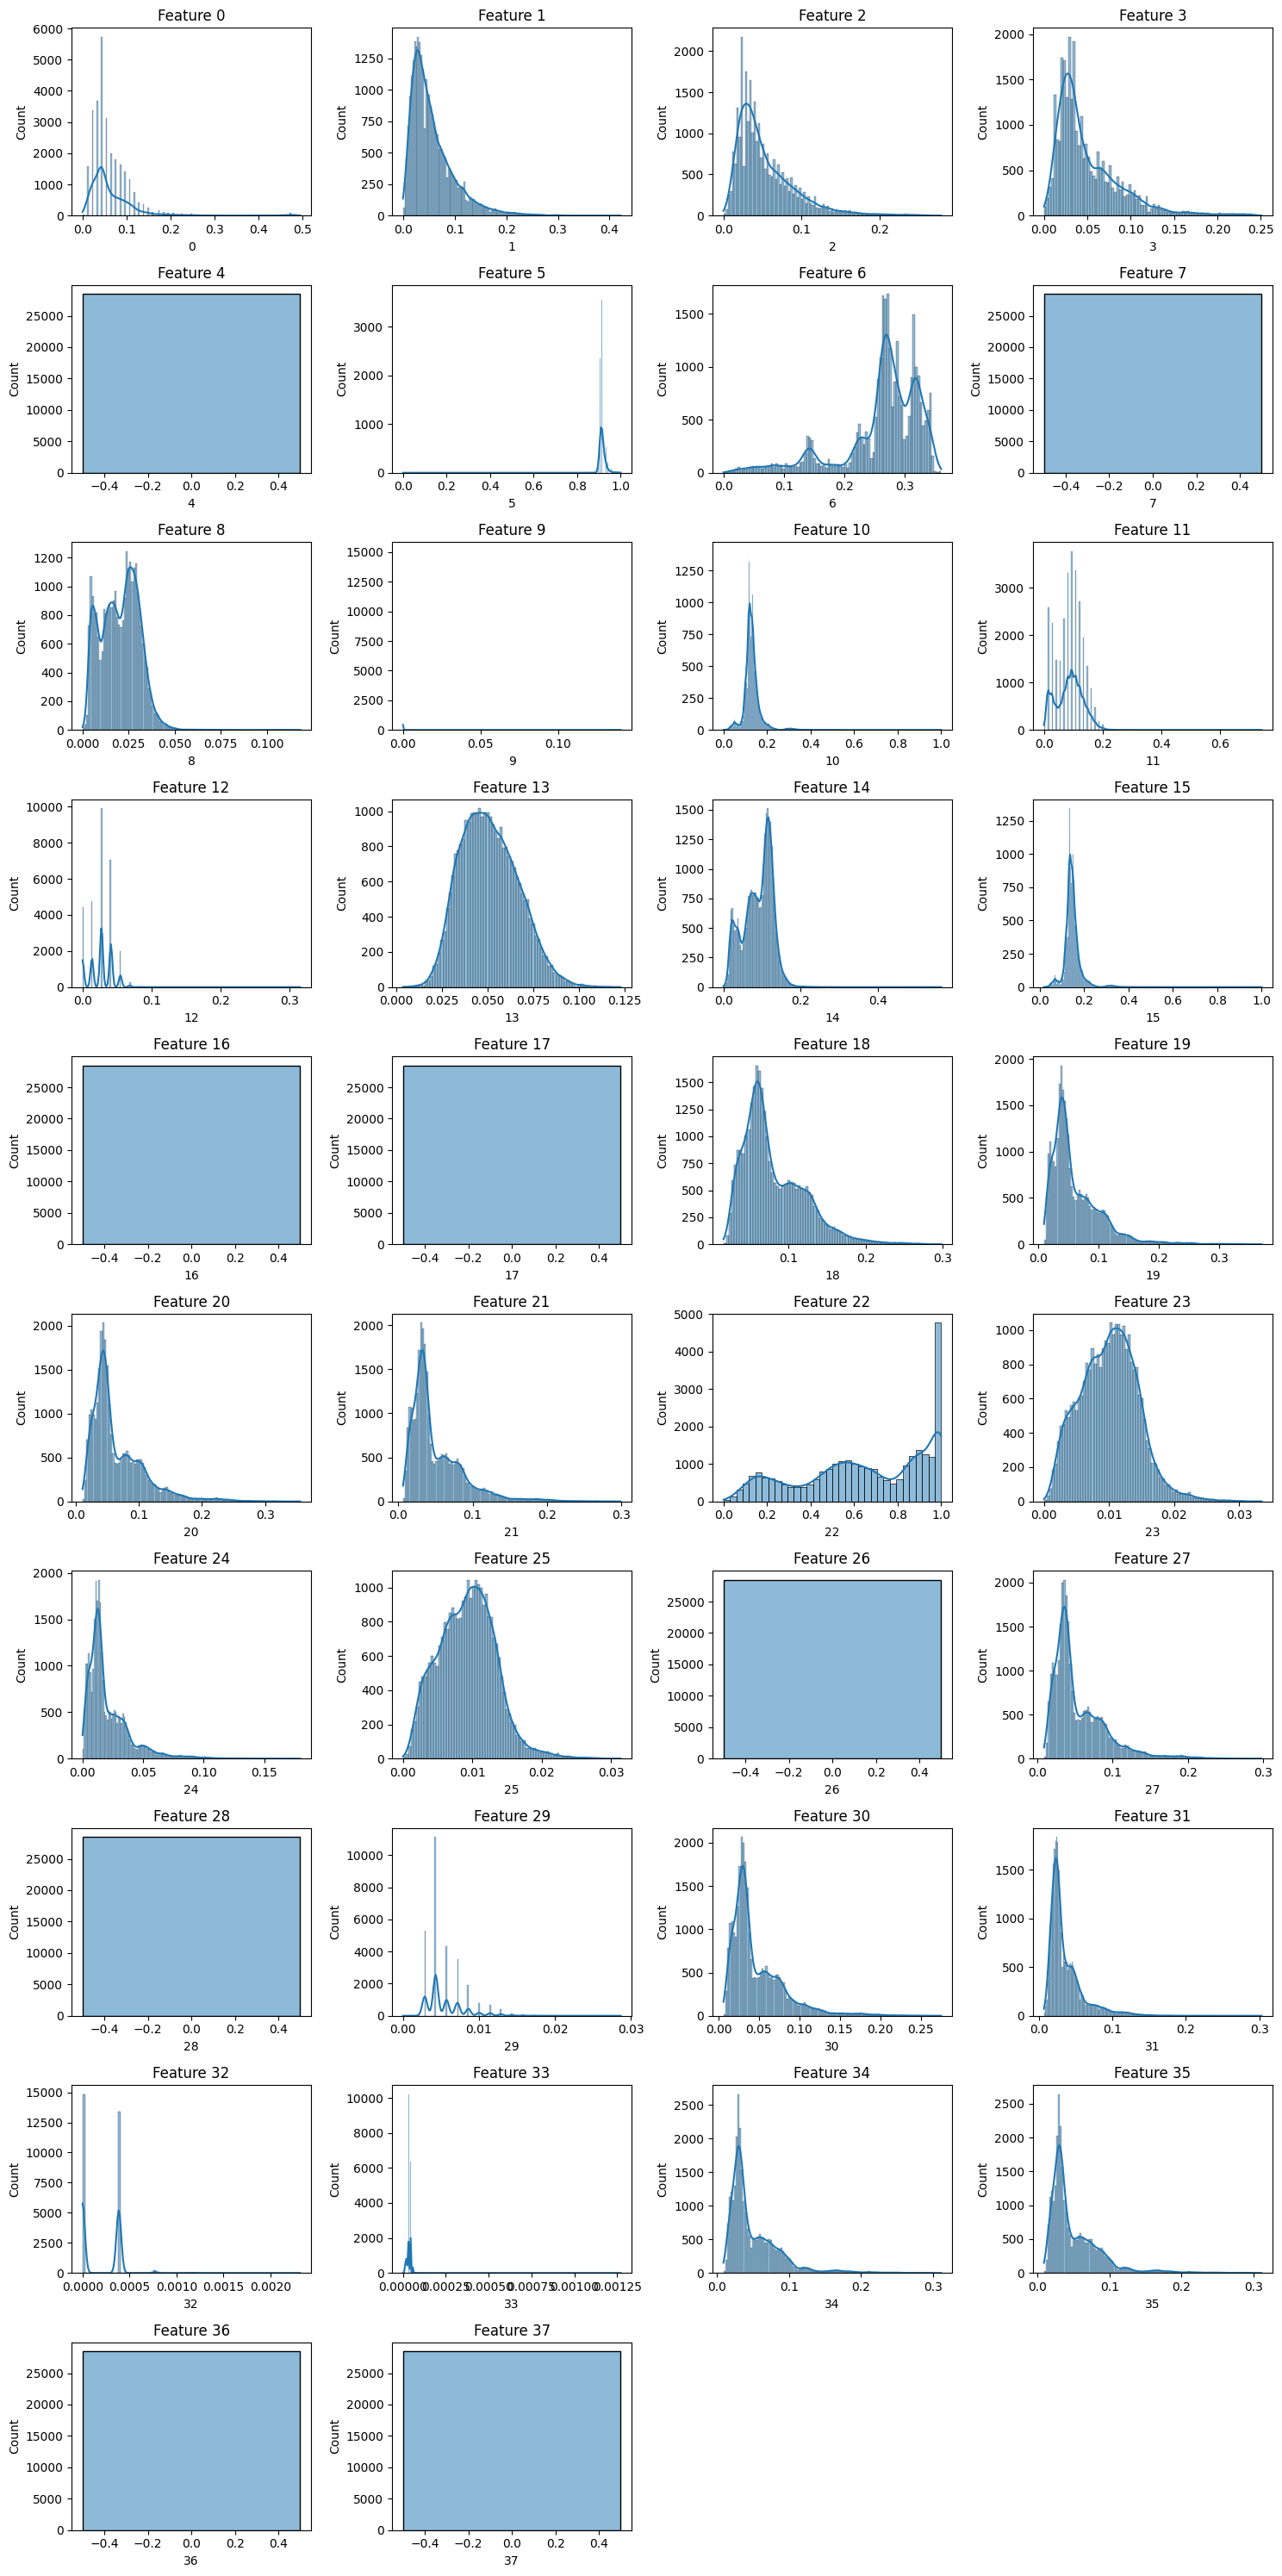

In [ ]:
# Plot histograms to understand the distribution of continuous variables and detecting outliers.

plt.figure(figsize=(15, 30))
for i, col in enumerate(df_train.columns.to_list()):
    plt.subplot(10, 4, i + 1)
    sns.histplot(x=col, data=df_train, kde=True)
    plt.title(f"Feature {col}")

plt.tight_layout()  # compact and spacing between plots
plt.show()


### 2.5 Missing Values

Missing values are checked before applying any preprocessing operation.

No imputation is applied unless missing values are identified.

In [ ]:
# ["0", "NA", "nan", "NULL", "Not Applicable", "None"]
missing_values = df_train.isnull().sum()

print("Number of missing values:")
print(missing_values)

Number of missing values:
0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
26    0
27    0
28    0
29    0
30    0
31    0
32    0
33    0
34    0
35    0
36    0
37    0
dtype: int64


### 2.6 Constant Features

Features with only one unique value are identified because they contain no variation in the training data.

Constant features are not automatically removed at this stage, since a feature that is constant during normal operation may vary during anomalous periods.

In [ ]:
constant_cols = df_train.columns[df_train.nunique() == 1]

print(constant_cols)


for col in constant_cols:
  print(
        col,
        "train:", df_train[col].nunique(),
        "test:", df_test[col].nunique()
    )


Index([4, 7, 16, 17, 26, 28, 36, 37], dtype='int64')
4 train: 1 test: 1
7 train: 1 test: 1
16 train: 1 test: 1
17 train: 1 test: 1
26 train: 1 test: 13
28 train: 1 test: 190
36 train: 1 test: 1
37 train: 1 test: 1


Based on the missing-value analysis and the boxplots/histograms:

1. Several features contain extreme values, but these should not be removed automatically because they may represent relevant anomaly signals.
2. No missing values were identified, so no imputation is required.
3. Some features are constant in the training set; if they vary in the test set, this variation may help indicate anomalous behaviour.

### 2.7 Anomaly Distribution

The `test_label` files are used to quantify the proportion of normal and anomalous observations for each machine.

The imbalance is evaluated for reporting and metric selection; no oversampling or undersampling is applied to the normal training data.

In [ ]:
# The model learns normal behavior from the training set and detects deviations
#in the test set. We check the class imbalance in the test data
#to choose appropriate evaluation metrics.

#returning a table showing the percentage of anomalies
label_folder = "/content/preprocess/test_label"

results = []

for filename in sorted(os.listdir(label_folder)):
  if filename.endswith(".csv"):
    path = os.path.join(label_folder, filename)
    labels = pd.read_csv(path, header=None)
    counts = labels[0].value_counts()

    normal = counts.get(0,0)
    anomaly = counts.get(1, 0)
    total = len(labels)

    results.append({
          "machine": os.path.splitext(filename)[0],
          "normal_points": normal,
          "anomaly_points": anomaly,
          "anomaly_%": anomaly / total * 100
    })

imbalance_df = pd.DataFrame(results)
imbalance_df = imbalance_df.sort_values(
        by="anomaly_%",
        ascending=False
  )
print(imbalance_df)



         machine  normal_points  anomaly_points  anomaly_%
5    machine-1-6          19981            3708  15.652835
9    machine-2-2          20867            2833  11.953586
6    machine-1-7          21299            2398  10.119424
0    machine-1-1          25785            2694   9.459602
11   machine-2-4          21995            1694   7.150998
16   machine-2-9          26967            1755   6.110299
8    machine-2-1          22524            1170   4.937959
26   machine-3-8          27333            1371   4.776338
20   machine-3-2          22594            1109   4.678733
18  machine-3-10          22646            1047   4.419027
24   machine-3-6          27532            1194   4.156513
12   machine-2-5          22709             980   4.136941
22   machine-3-4          22710             977   4.124625
2    machine-1-3          22886             817   3.446821
7    machine-1-8          22936             763   3.219545
3    machine-1-4          22987             720   3.0370

In [ ]:
def plot_machine(machine):
  row = imbalance_df[imbalance_df["machine"] == machine].iloc[0]

  values = [
      row["normal_points"],
      row["anomaly_points"]
  ]

  labels = ["Normal", "Anomaly"]

  plt.figure(figsize=(6, 6))
  plt.pie(
      values,
      labels=labels,
      autopct="%1.1f%%",
      startangle=90
  )

  plt.title(f"Normal vs Anomaly – {machine}")
  plt.show()

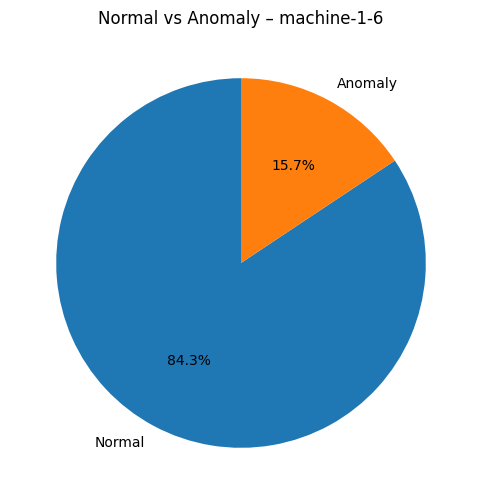

In [ ]:
plot_machine(imbalance_df["machine"].iloc[0])

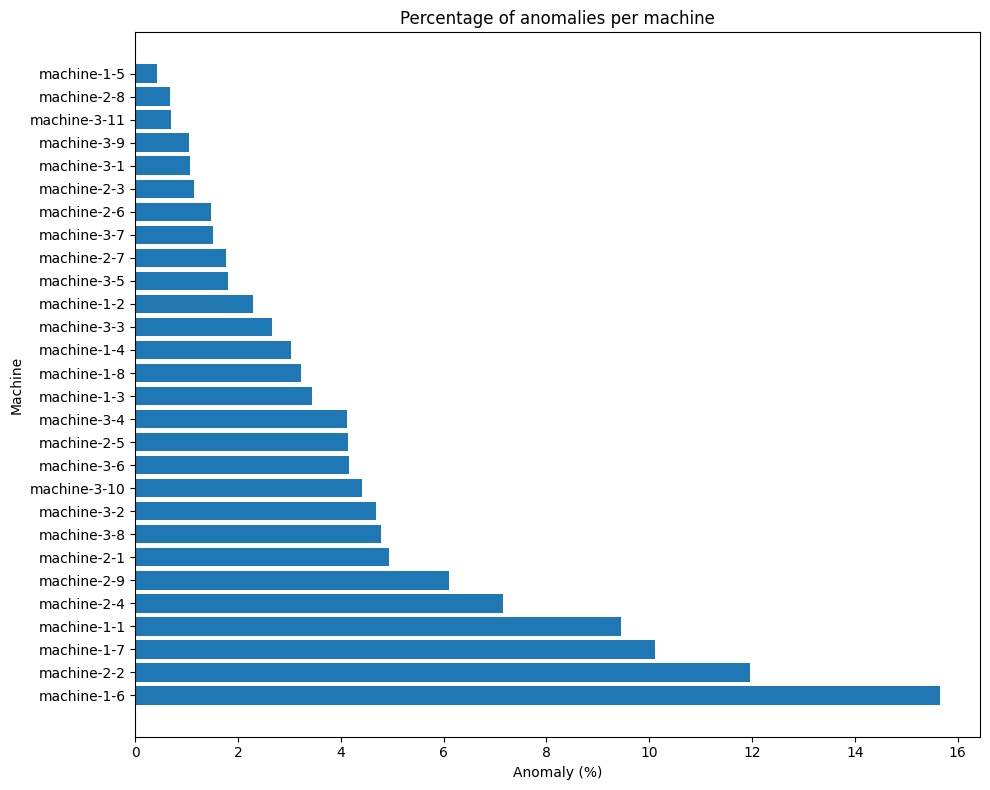

In [ ]:
plt.figure(figsize=(10, 8))

plt.barh(
    imbalance_df["machine"],
    imbalance_df["anomaly_%"]
)

plt.xlabel("Anomaly (%)")
plt.ylabel("Machine")
plt.title("Percentage of anomalies per machine")

plt.tight_layout()
plt.show()

## 3. Data Preprocessing

Each SMD machine is processed independently.

The preprocessing pipeline is:

**Load → Inspect → Validate → Standardize → Temporal Windowing**

The same preprocessing strategy is applied consistently to the training and test data while preventing information leakage.


### 3.1 Temporal Windowing

The multivariate time series is divided into overlapping temporal windows so that the model can learn temporal dependencies rather than processing individual observations independently.

For a window size of 100, each model input has the form:

`100 timesteps × 38 features`

and the complete processed dataset has the shape:

`(number_of_windows, 100, 38)`.

In [ ]:
def create_windows(data, window_size=100):
  windows=[]

  for i in range(len(data) - window_size + 1):
    windows.append(data[i:i+window_size])

  return np.array(windows)

### 3.2 Complete Preprocessing Pipeline

The complete preprocessing procedure is encapsulated in a reusable function and applied independently to every machine.

For each machine:

1. train and test files are loaded;
2. their structure is verified;
3. missing and constant features are identified;
4. the scaler is fitted on the training data;
5. train and test data are standardized;
6. temporal windows are generated.

The resulting sequences are subsequently used as input to the anomaly detection models.

In [ ]:
def preprocess_machine(train_path, test_path, window_size=100):
  # 1. Load
  df_train = pd.read_csv(train_path, header=None, dtype="float32")
  df_test = pd.read_csv(test_path, header=None, dtype="float32")

  #2. Inspect
  print("Train info:", df_train.info())
  print("Test info:", df_train.info())

  #3. Checking missing values
  print("Train total missing values:", df_train.isnull().sum().sum())
  print("Test total missing values:", df_test.isnull().sum().sum())

  #4. Checking constant features
  constant_cols = df_train.columns[df_train.nunique() == 1].tolist()
  print("Constant features:", constant_cols)

  # 5. Standardization
  scaler = StandardScaler()

  train_scaled = scaler.fit_transform(df_train)
  test_scaled = scaler.transform(df_test)

  # 6. Windowing
  train_windows = create_windows(train_scaled, window_size)
  test_windows = create_windows(test_scaled, window_size)

  print("Train windows:", train_windows.shape)
  print("Test windows:", test_windows.shape)

  return train_windows, test_windows, scaler


In [ ]:
train_folder = "/content/preprocess/train"
test_folder = "/content/preprocess/test"

processed_machines = {}

for filename in sorted(os.listdir(train_folder)):
  if filename.endswith(".csv"):

    machine_name = os.path.splitext(filename[0])
    train_path = os.path.join(train_folder, filename)
    test_path = os.path.join(test_folder, filename)

    print(f"\n##### {filename} #####")
    train_windows, test_windows, scaler = preprocess_machine(
        train_path,
        test_path,
        window_size=100
    )

    processed_machines[machine_name] = {
        "train": train_windows,
         "test": test_windows,
         "scaler": scaler
    }


##### machine-1-1.csv #####
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28479 entries, 0 to 28478
Data columns (total 38 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       28479 non-null  float32
 1   1       28479 non-null  float32
 2   2       28479 non-null  float32
 3   3       28479 non-null  float32
 4   4       28479 non-null  float32
 5   5       28479 non-null  float32
 6   6       28479 non-null  float32
 7   7       28479 non-null  float32
 8   8       28479 non-null  float32
 9   9       28479 non-null  float32
 10  10      28479 non-null  float32
 11  11      28479 non-null  float32
 12  12      28479 non-null  float32
 13  13      28479 non-null  float32
 14  14      28479 non-null  float32
 15  15      28479 non-null  float32
 16  16      28479 non-null  float32
 17  17      28479 non-null  float32
 18  18      28479 non-null  float32
 19  19      28479 non-null  float32
 20  20      28479 non-null  float32
 21  21    